# Netflix ETL and Data Analysis

This project uses Python, Pandas, and SQL to clean, transform, and analyze Netflix Movies and TV Shows data.

The analysis uses 2,000 records from the original dataset of 8,807 records.

In [1]:
import pandas as pd

df = pd.read_csv("data/netflix_sample.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (2000, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)  

Dataset shape: (2000, 12)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data types:
show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
show_id           0
type              0
title             0
director        652
cast            200
country         390
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
description       0
dtype: int64


In [4]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate show IDs:", df["show_id"].duplicated().sum())

Duplicate rows: 0
Duplicate show IDs: 0


In [5]:
print("Content types:")
print(df["type"].value_counts())

print("\nNumber of unique ratings:", df["rating"].nunique())

print("\nRelease year range:")
print(df["release_year"].min(), "-", df["release_year"].max())

Content types:
type
Movie      1305
TV Show     695
Name: count, dtype: int64

Number of unique ratings: 10

Release year range:
1945 - 2021


In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,2000,2000,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,2000,2,Movie,1305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,2000,2000,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,1348,1145,Rajiv Chilaka,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,1800,1762,"Vatsal Dubey, Julie Tejwani, Rupa Bhimani, Jig...",14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,1610,236,United States,600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,2000,335,"July 1, 2021",60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,2000.0,NaN,NaN,NaN,2015.8625,8.364842,1945.0,2014.0,2020.0,2021.0,2021.0
rating,2000,10,TV-MA,677,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,2000,165,1 Season,413,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data Cleaning

The dataset contains missing values in columns such as director, cast, and country. I will clean these values and remove any duplicate records.

In [7]:
# Create a copy for cleaning
cleaned_df = df.copy()

# Remove duplicate records
cleaned_df = cleaned_df.drop_duplicates()

# Fill missing text values
for column in ["director", "cast", "country"]:
    cleaned_df[column] = cleaned_df[column].fillna("Unknown")

# Check missing values
print(cleaned_df.isnull().sum())

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [8]:
print("Cleaned dataset shape:", cleaned_df.shape)

cleaned_df.head()

Cleaned dataset shape: (2000, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 4. Data Transformation

In this step, I will create additional columns from the date added and release year to make the dataset easier to analyze.

In [9]:
# Convert date_added to datetime format
cleaned_df["date_added"] = pd.to_datetime(
    cleaned_df["date_added"].str.strip(),
    format="mixed",
    errors="coerce"
)

# Create new columns
cleaned_df["date_added_year"] = cleaned_df["date_added"].dt.year
cleaned_df["date_added_month"] = cleaned_df["date_added"].dt.month
cleaned_df["content_age"] = 2026 - cleaned_df["release_year"]

cleaned_df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,date_added_year,date_added_month,content_age
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,9,6
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,9,5
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,9,5
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021,9,5
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021,9,5


In [10]:
# Separate movies and TV shows
movies_df = cleaned_df[cleaned_df["type"] == "Movie"].copy()
tv_shows_df = cleaned_df[cleaned_df["type"] == "TV Show"].copy()

print("Total records:", len(cleaned_df))
print("Movies:", len(movies_df))
print("TV Shows:", len(tv_shows_df))

Total records: 2000
Movies: 1305
TV Shows: 695


## 5. Data Loading

I will load the transformed Netflix dataset into an SQLite database for SQL analysis.

In [11]:
import sqlite3
from pathlib import Path

# Create the database folder
Path("database").mkdir(exist_ok=True)

# Connect to the SQLite database
conn = sqlite3.connect("database/netflix.db")

# Load the transformed data into a table
cleaned_df.to_sql(
    "netflix_titles",
    conn,
    if_exists="replace",
    index=False
)

# Check the number of records
result = pd.read_sql(
    "SELECT COUNT(*) AS total_records FROM netflix_titles",
    conn
)

print(result)

conn.close()

   total_records
0           2000


## 6. SQL Analysis

I will use SQL queries to analyze the Netflix dataset and identify useful patterns.

In [12]:
conn = sqlite3.connect("database/netflix.db")

query = """
SELECT type, COUNT(*) AS total_titles
FROM netflix_titles
GROUP BY type
ORDER BY total_titles DESC;
"""

pd.read_sql(query, conn)

,type,total_titles
0,Movie,1305
1,TV Show,695


In [13]:
query = """
SELECT rating, COUNT(*) AS total_titles
FROM netflix_titles
WHERE rating IS NOT NULL
GROUP BY rating
ORDER BY total_titles DESC;
"""

pd.read_sql(query, conn)

,rating,total_titles
0,TV-MA,677
1,TV-14,456
2,R,221
3,PG-13,163
4,TV-PG,149
5,TV-Y7,99
6,TV-Y,98
7,PG,71
8,TV-G,62
9,G,4


In [14]:
query = """
SELECT release_year, COUNT(*) AS total_titles
FROM netflix_titles
GROUP BY release_year
ORDER BY total_titles DESC
LIMIT 10;
"""

pd.read_sql(query, conn)

,release_year,total_titles
0,2021,590
1,2020,449
2,2019,149
3,2018,124
4,2016,70
5,2017,65
6,2013,55
7,2015,47
8,2014,45
9,2012,39


## 7. Data Visualization

A bar chart helps compare the number of movies and TV shows in the dataset.

Matplotlib is building the font cache; this may take a moment.


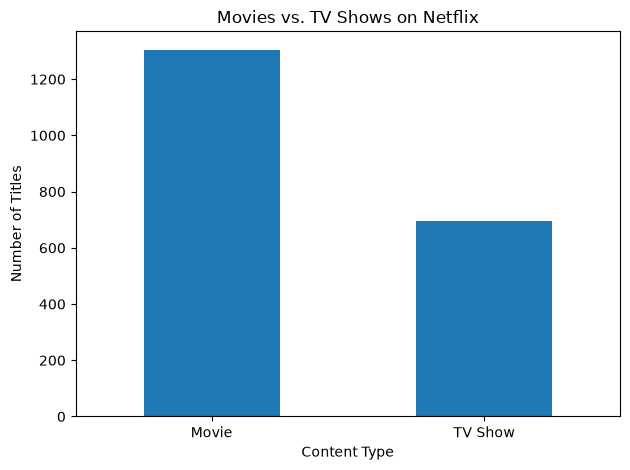

In [15]:
import matplotlib.pyplot as plt

content_counts = df["type"].value_counts()

content_counts.plot(kind="bar")

plt.title("Movies vs. TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Key Findings

- The dataset contains 2,000 Netflix titles: 1,305 movies and 695 TV shows.
- Movies make up the majority of the selected records.
- The dataset contains missing values in director, cast, and country, which were handled during cleaning.
- SQL queries helped identify popular release years and the most common content ratings.
- Data visualization makes it easier to compare movies and TV shows.

In [16]:
query = """
SELECT country, COUNT(*) AS total_titles
FROM netflix_titles
WHERE country IS NOT NULL
  AND country != 'Unknown'
GROUP BY country
ORDER BY total_titles DESC
LIMIT 10;
"""

pd.read_sql(query, conn)

,country,total_titles
0,United States,600
1,India,145
2,United Kingdom,62
3,Japan,58
4,South Korea,42
5,Turkey,31
6,Nigeria,30
7,Philippines,27
8,Canada,27
9,"United States, Canada",26


In [17]:
query = """
SELECT listed_in, COUNT(*) AS total_titles
FROM netflix_titles
GROUP BY listed_in
ORDER BY total_titles DESC
LIMIT 10;
"""

pd.read_sql(query, conn)

,listed_in,total_titles
0,"Dramas, International Movies",82
1,Kids' TV,61
2,"Comedies, Dramas, International Movies",58
3,Children & Family Movies,58
4,"Children & Family Movies, Comedies",54
5,Documentaries,50
6,Action & Adventure,49
7,"Dramas, International Movies, Romantic Movies",47
8,"Dramas, Independent Movies, International Movies",39
9,Reality TV,37


In [18]:
query = """
SELECT type,
       ROUND(AVG(release_year), 1) AS average_release_year
FROM netflix_titles
GROUP BY type;
"""

pd.read_sql(query, conn)

,type,average_release_year
0,Movie,2014.3
1,TV Show,2018.8


In [19]:
query = """
SELECT type, COUNT(*) AS total_titles
FROM netflix_titles
GROUP BY type
HAVING COUNT(*) > 100
ORDER BY total_titles DESC;
"""

pd.read_sql(query, conn)

,type,total_titles
0,Movie,1305
1,TV Show,695


In [20]:
query = """
SELECT title, duration
FROM netflix_titles
WHERE type = 'Movie'
  AND duration LIKE '%min'
ORDER BY CAST(REPLACE(duration, ' min', '') AS INTEGER) DESC
LIMIT 10;
"""

pd.read_sql(query, conn)

,title,duration
0,Headspace: Unwind Your Mind,273 min
1,Once Upon a Time in America,229 min
2,Lagaan,224 min
3,Seven Souls in the Skull Castle: Season Moon K...,212 min
4,Seven Souls in the Skull Castle: Season Moon J...,204 min
5,Magnolia,189 min
6,Seven Souls in the Skull Castle: Season Wind,185 min
7,King of Boys,182 min
8,Seven Souls in the Skull Castle: Season Bird,182 min
9,Banyuki,182 min
